# OMIP runs: global-mean SST & wind-stress perturbation

**What's in this notebook**

- Global-mean SST time series across OMIP runs.
- Wind-stress (taux) perturbation maps.

_Split from `omip_compare.ipynb` (global mean). Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [1]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [2]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [3]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


[load_state] loaded 215 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, basin_cmip, basin_era5, basin_jra55, basin_noaa, basin_omip ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

# global mean 

In [13]:

mod_labs = ['MRI-ESM2-0', 'FGOALS-f3-L','EC-EARTH3','ACCESS-OM2-JRA55-cycle6_iaf','ACCESS-OM2-ERA5']

save_directory = '/Users/isabelaconde/Desktop/data/omip/tos/'

file_paths = [f"{save_directory}tos_global_{model}_1982-2018_gr.nc" for model in mod_labs]
gr_omip = {}

td = datetime.strptime("1982-01-01", "%Y-%m-%d")
k = 444
d = pd.date_range(td, periods=k, freq='MS')


for i, path in enumerate(file_paths):
    ds = xr.open_dataarray(path)
    ds = ds.assign_coords({'time': d})
    gr_omip[mod_labs[i]] = xr.open_dataarray(path)


In [14]:


mod_labs = ['MRI-ESM2-0', 'FGOALS-f3-L', 'EC-EARTH3']
# , 'ACCESS-OM2-JRA55-cycle6_iaf', 'ACCESS-OM2-ERA5'
plt.figure(figsize=(10, 5))

for label in mod_labs:
    ts = dict_global_mean[label]
    annual_ts = ts.resample(time="1Y").mean()
    annual_ts.plot(label=label)

plt.ylabel('°C')
plt.ylim([17.8, 18.8])
plt.xlabel('Time')
plt.title('Global Mean Temperature Time Series')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

KeyError: 'MRI-ESM2-0'

<Figure size 1000x500 with 0 Axes>

In [9]:
taux_perturb  = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_era5_uas_tau_x_trend_1983-2017_gr.nc')
taux_control  = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/control_tau_x_trend_1983-2017_gr.nc')

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_54473/3785788988.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


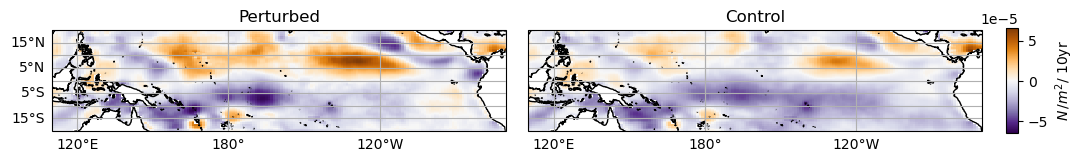

In [10]:
pert = taux_perturb
ctrl = taux_control

# Projection centered on the Pacific; data are standard lon/lat
proj = ccrs.PlateCarree(central_longitude=180)  # shifts view so Pacific is centered
pc0  = ccrs.PlateCarree()                       # CRS of the data
extent = [110, 290, -20, 20]                    # tropical Pacific only

fig = plt.figure(figsize=(12, 7))
gs = GridSpec(1, 2, figure=fig, wspace=0.05, hspace=0.10)

axes = [fig.add_subplot(gs[0, 0], projection=proj),
        fig.add_subplot(gs[0, 1], projection=proj)]

ims = []
for ax, da, title in zip(axes[:2], [pert, ctrl], ['Perturbed', 'Control']):
    im = ax.pcolormesh(da.lon, da.lat, da, cmap='PuOr_r',  transform=pc0)
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# # hide bottom row for now (keeps a 2×2 layout)
# for ax in axes[2:]:
#     ax.set_visible(False)
gls = []
for ax in axes:
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gls.append(gl)

gls[1].left_labels = False           # cartopy ≥0.21


cax = fig.add_axes([0.92, 0.42, 0.01, 0.15])
fig.colorbar(ims[0], cax=cax, label=r'$N\,/m^2/ \ 10$yr')



plt.tight_layout()


NameError: name 'gr_omip_trend' is not defined

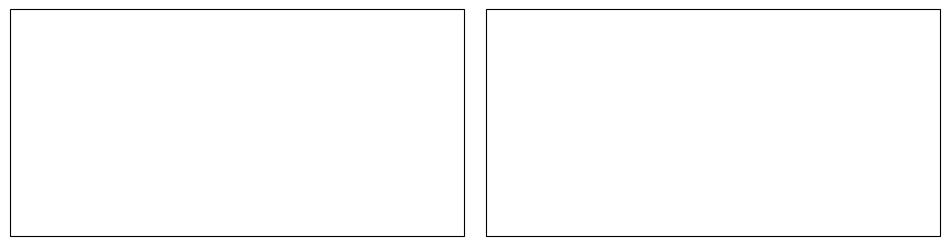

In [15]:

# Projection centered on the Pacific; data are standard lon/lat
proj = ccrs.PlateCarree(central_longitude=180)  # shifts view so Pacific is centered
pc0  = ccrs.PlateCarree()                       # CRS of the data
extent = [110, 290, -20, 20]                    # tropical Pacific only

fig = plt.figure(figsize=(12, 7))
gs = GridSpec(1, 2, figure=fig, wspace=0.05, hspace=0.10)

axes = [fig.add_subplot(gs[0, 0], projection=proj),
        fig.add_subplot(gs[0, 1], projection=proj)]

ims = []
for ax, da, title in zip(axes[:2], [gr_omip_trend[-2]*12*10, gr_omip_trend[-3]*10*12], ['ERA5','JRA55-do']):
    im = ax.pcolormesh(da.lon, da.lat, da, cmap='RdBu_r', vmin=-0.3, vmax=0.3, transform=pc0)
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# # hide bottom row for now (keeps a 2×2 layout)
# for ax in axes[2:]:
#     ax.set_visible(False)
gls = []
for ax in axes:
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gls.append(gl)

gls[1].left_labels = False           # cartopy ≥0.21


cax = fig.add_axes([0.92, 0.42, 0.01, 0.15])
fig.colorbar(ims[0], cax=cax, label=r'$^{\circ}$C$ / \, 10$ yrs')



plt.tight_layout()

NameError: name 'gr_omip_trend' is not defined

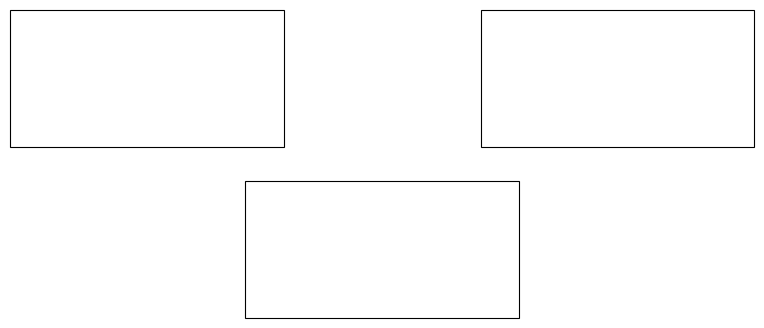

In [12]:
# Projection centered on the Pacific; data are standard lon/lat
proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

fig = plt.figure(figsize=(12, 4))

# 2 rows, 4 cols:
# - top-left spans cols 0:2
# - top-right spans cols 2:4
# - bottom spans cols 1:3  (centered)
gs = GridSpec(2, 4, figure=fig, wspace=0.05, hspace=0.25, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0, 0:2], projection=proj)
ax2 = fig.add_subplot(gs[0, 2:4], projection=proj)
ax3 = fig.add_subplot(gs[1, 1:3], projection=proj)  # centered

axes = [ax1, ax2, ax3]

data_list  = [gr_omip_trend[-1]*12*10, gr_omip_trend[-2]*12*10, noaa_trend*12*10]
title_list = ['ACCESS-OM2 forced by ERA5', 'ACCESS-OM2 forced by JRA55-do', 'NOAA OISST']

ims = []
for ax, da, title in zip(axes, data_list, title_list):
    im = ax.pcolormesh(da.lon, da.lat, da, cmap='RdBu_r',
                       vmin=-0.3, vmax=0.3, transform=pc0)
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

gls = []
for ax in axes:
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gls.append(gl)

gls[1].left_labels = False  # keep only left labels on the left-most top panel
gls[2].left_labels = False  # (optional) hide left labels on the bottom centered panel

# colorbar (shared)
cax = fig.add_axes([0.92, 0.30, 0.015, 0.40])
fig.colorbar(ims[0], cax=cax, label=r'$^{\circ}$C$ / \, 10$ yrs')


In [ ]:
fig, axes = plt.subplots(figsize=(12, 6))
# -------------------------
# CMIP + envelope
# -------------------------
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  label='0.1–0.9 Decile Range')
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')


# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    label='OMIP Model Spread'
)
# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color='k', label='NOAA OISST')
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced', color='firebrick')

(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
# (perturb_percent_era5_uas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas trend', color='cyan')
(perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas, vas trend', color='cyan')
((perturb_percent_winds_mean_trend)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas & vas trend and mean state', color='b')
((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas, vas', color='violet')

(perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55-do froced with ERA5 rsds, rlds trend', color='orange')
((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 huss, tas trend', color='limegreen')
# # # ((perturb_percent_all_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 all-ish trends', color='orange',lw = 1.5)
# (control_percent_trend*12*10).plot(ax=axes, label='', color='firebrick')
(control_percent_trend*12*10).plot(ax=axes, label='', color='firebrick')


fig.subplots_adjust(right=0.72)   # tweak 0.72–0.8 depending on how wide your legend is

# grab handles/labels from the axes and put legend to the right (outside)
handles, labels = axes.get_legend_handles_labels()
axes.legend(
    handles, labels,
    loc="center left",
    bbox_to_anchor=(1.02, 0.76),   # (x,y) in axes coordinates; x>1 puts it outside
    borderaxespad=0.0,
    fontsize=9,
    frameon=False
)

# axes.legend(frameon=False, loc='lower right')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
# axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylim(-0.28, 0.29)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile', fontsize=14)
outpath = "/Users/isabelaconde/Desktop/trend_percentile.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

In [ ]:
fig, axes = plt.subplots(figsize=(9, 6))
# -------------------------
# CMIP + envelope
# -------------------------
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  label='0.1–0.9 Decile Range')
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')


# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    label='OMIP Model Spread'
)
# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color='k', label='NOAA OISST')
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced', color='firebrick')

(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
# (perturb_percent_era5_uas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas trend', color='cyan')
(perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas, vas trend', color='cyan')
((perturb_percent_winds_mean_trend)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas & vas trend and mean state', color='b')
((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas, vas', color='violet')

(perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55-do froced with ERA5 rsds, rlds trend', color='orange')
((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 huss, tas trend', color='limegreen')
# # # ((perturb_percent_all_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 all-ish trends', color='orange',lw = 1.5)
# (control_percent_trend*12*10).plot(ax=axes, label='', color='firebrick')
(control_percent_trend*12*10).plot(ax=axes, label='', color='firebrick')


# leave space at bottom for legend
fig.subplots_adjust(bottom=0.3)

handles, labels = axes.get_legend_handles_labels()

axes.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,   # increase if needed
    fontsize=9,
    frameon=False
)

# axes.legend(frameon=False, loc='lower right')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
# axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylim(-0.28, 0.29)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile', fontsize=14)
outpath = "/Users/isabelaconde/Desktop/trend_percentile.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

In [ ]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())
